#  Grad-CAM with ResNet50 — Intel Image Classification
**Dataset:** [Intel Image Classification](https://www.kaggle.com/datasets/puneet6060/intel-image-classification)  
**Model:** ResNet50 (transfer learning + two-phase fine-tuning)  
**Explainability:** Gradient-weighted Class Activation Mapping (Grad-CAM)



#  Step 1 — Check GPU

In [ ]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)
print("GPUs available:", tf.config.list_physical_devices('GPU'))
!nvidia-smi

TensorFlow version: 2.20.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mon Aug 24 09:54:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                             

##  Step 2 — Imports

In [ ]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import classification_report, confusion_matrix

print("All imports successful ✅")

All imports successful ✅


##  Step 3 — Download Dataset from Kaggle


In [ ]:
import kagglehub

# Download latest version of the Intel Image Classification dataset
dataset_path = kagglehub.dataset_download("puneet6060/intel-image-classification")

print("Path to dataset files:", dataset_path)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Path to dataset files: /kaggle/input/intel-image-classification


## Step 4 — Set Up Data Generators
- 80 / 20 train-validation split from the training folder  
- **Stronger augmentation** applied to training data (vertical flip + brightness jitter added)  
- Validation and test data: rescale only, no augmentation, no shuffle  
- `seed=42` keeps train/val split deterministic across runs

In [ ]:
import os

IMG_SIZE   = (224, 224)
BATCH_SIZE = 32
SEED       = 42

# Link directories dynamically to the kagglehub download path
train_dir = os.path.join(dataset_path, "seg_train/seg_train")
test_dir  = os.path.join(dataset_path, "seg_test/seg_test")

# 1. Generator for TRAINING (Data Augmentation applied)
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    brightness_range=[0.8, 1.2]
)

# 2. Generator for VALIDATION (Only Rescaling applied)
val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    seed=SEED
)

val_generator = val_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    seed=SEED
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

class_names = list(train_generator.class_indices.keys())
NUM_CLASSES  = len(class_names)
print("Classes:", class_names)
print(f"Num classes: {NUM_CLASSES}")
print(f"Train batches: {len(train_generator)} | Val batches: {len(val_generator)} | Test batches: {len(test_generator)}")

Found 11230 images belonging to 6 classes.
Found 2804 images belonging to 6 classes.
Found 3000 images belonging to 6 classes.
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Num classes: 6
Train batches: 351 | Val batches: 88 | Test batches: 94


## 🏗️ Step 5 — Build ResNet50 Model (Two-Phase Strategy)
**Phase 1 (warm-up):** All ResNet50 layers frozen → only the new head trains.  
**Phase 2 (fine-tune):** Last 30 layers of ResNet50 unfrozen → lower LR fine-tuning.

In [ ]:
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# ── Phase 1: freeze entire base ───────────────────────────────────────
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)          # added: stabilises training of new head
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
output_layer = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output_layer)

frozen_count    = sum(1 for l in base_model.layers if not l.trainable)
trainable_count = sum(1 for l in base_model.layers if l.trainable)
print(f"Base model — frozen: {frozen_count} | trainable: {trainable_count}")
model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Base model — frozen: 175 | trainable: 0


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,121,990 (92.02 MB)

 Trainable params: 530,182 (2.02 MB)

 Non-trainable params: 23,591,808 (90.00 MB)

##  Step 6 — Phase 1: Compile & Train (Head Only)
Learning rate 1e-3, patience=5, up to 10 epochs.  
Goal: bring the new classification head to a good starting point before touching ResNet weights.

In [ ]:
model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_phase1 = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint(
        'best_phase1.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)
]

print("Phase 1 — training head only...")
history_p1 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    callbacks=callbacks_phase1
)
print("Phase 1 complete ✅")

Phase 1 — training head only...
Epoch 1/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 585ms/step - accuracy: 0.4151 - loss: 1.4588
Epoch 1: val_accuracy improved from None to 0.54815, saving model to best_phase1.keras

Epoch 1: finished saving model to best_phase1.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 240s 641ms/step - accuracy: 0.4592 - loss: 1.3479 - val_accuracy: 0.5481 - val_loss: 1.3047 - learning_rate: 0.0010
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 497ms/step - accuracy: 0.5020 - loss: 1.2269
Epoch 2: val_accuracy improved from 0.54815 to 0.62482, saving model to best_phase1.keras

Epoch 2: finished saving model to best_phase1.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 183s 523ms/step - accuracy: 0.5127 - loss: 1.2069 - val_accuracy: 0.6248 - val_loss: 0.9740 - learning_rate: 0.0010
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 484ms/step - accuracy: 0.5281 - loss: 1.1484
Epoch 3: val_accuracy improved from 0.62482 to 0.64194, saving model to best_phase1.keras

Epoch 3: finished saving model to best_p

##  Step 7 — Phase 2: Unfreeze & Fine-Tune (Last 30 Layers)
Lower LR (1e-5) to avoid destroying pre-trained features. Patience=5, up to 20 more epochs.

In [ ]:
# Unfreeze last 30 layers of the base model
for layer in base_model.layers[-30:]:
    layer.trainable = True

fine_tune_count = sum(1 for l in base_model.layers if l.trainable)
print(f"Fine-tuning {fine_tune_count} / {len(base_model.layers)} base-model layers")

# MUST re-compile after changing trainability
model.compile(
    optimizer=Adam(learning_rate=1e-5),   # much lower LR for fine-tuning
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_phase2 = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint(
        'best_phase2.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7, verbose=1)
]

print("Phase 2 — fine-tuning last 30 layers...")
history_p2 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20,
    callbacks=callbacks_phase2
)
print("Phase 2 complete ")

Fine-tuning 30 / 175 base-model layers
Phase 2 — fine-tuning last 30 layers...
Epoch 1/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 514ms/step - accuracy: 0.4197 - loss: 1.8887
Epoch 1: val_accuracy improved from None to 0.48395, saving model to best_phase2.keras

Epoch 1: finished saving model to best_phase2.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 215s 560ms/step - accuracy: 0.4607 - loss: 1.6175 - val_accuracy: 0.4840 - val_loss: 1.5073 - learning_rate: 1.0000e-05
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 488ms/step - accuracy: 0.5092 - loss: 1.3396
Epoch 2: val_accuracy improved from 0.48395 to 0.60271, saving model to best_phase2.keras

Epoch 2: finished saving model to best_phase2.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 181s 514ms/step - accuracy: 0.5199 - loss: 1.2938 - val_accuracy: 0.6027 - val_loss: 1.0793 - learning_rate: 1.0000e-05
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 489ms/step - accuracy: 0.5340 - loss: 1.2049
Epoch 3: val_accuracy improved from 0.60271 to 0.65407, saving model to best

##  Step 8 — Save Final Model

In [ ]:
model.save("resnet50_gradcam_improved.keras")
print("Model saved → resnet50_gradcam_improved.keras ✅")

Model saved → resnet50_gradcam_improved.keras ✅


##  Step 9 — Training Curves (Both Phases)

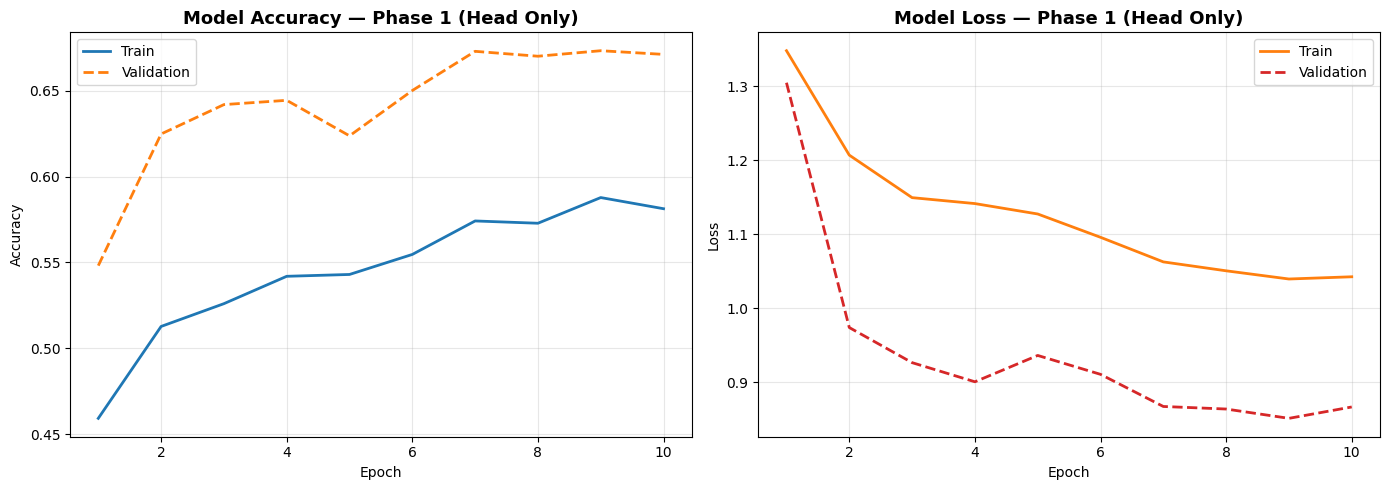

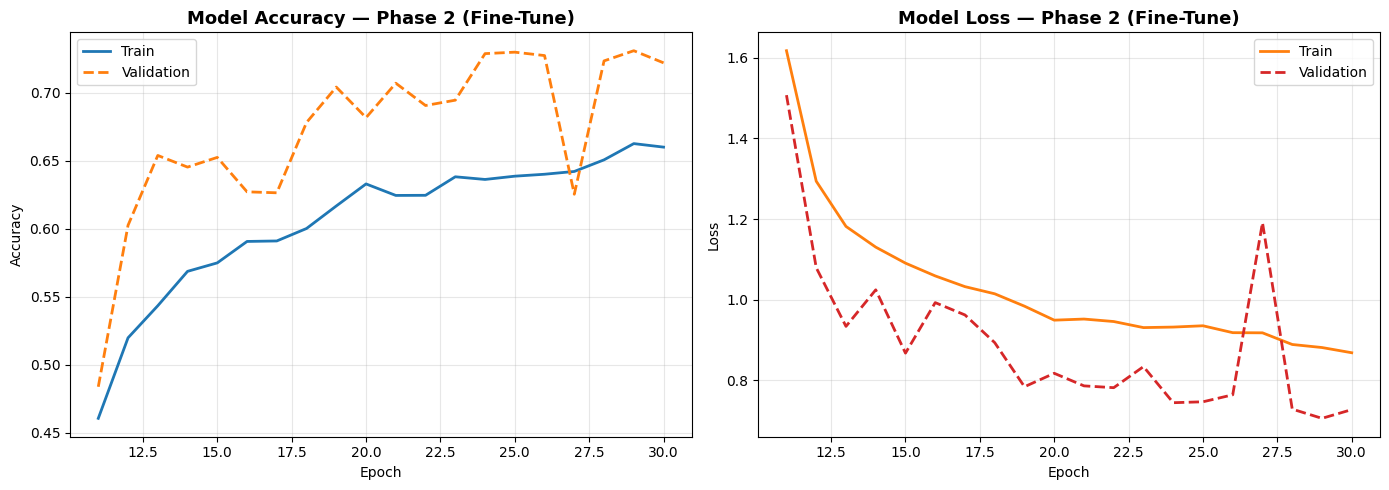

In [ ]:
import matplotlib.pyplot as plt

def plot_history(hist, title_suffix="", offset=0):
    epochs = range(offset + 1, offset + len(hist.history['accuracy']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epochs, hist.history['accuracy'],     label='Train',      linewidth=2)
    axes[0].plot(epochs, hist.history['val_accuracy'], label='Validation', linewidth=2, linestyle='--')
    axes[0].set_title(f'Model Accuracy {title_suffix}', fontsize=13, fontweight='bold')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(epochs, hist.history['loss'],     label='Train',      linewidth=2, color='tab:orange')
    axes[1].plot(epochs, hist.history['val_loss'], label='Validation', linewidth=2, color='tab:red', linestyle='--')
    axes[1].set_title(f'Model Loss {title_suffix}', fontsize=13, fontweight='bold')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
    axes[1].legend(); axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_history(history_p1, title_suffix="— Phase 1 (Head Only)", offset=0)
plot_history(history_p2, title_suffix="— Phase 2 (Fine-Tune)", offset=len(history_p1.history['accuracy']))

##  Step 10 — Evaluate on Test Set

In [ ]:

test_generator.reset()
loss, acc = model.evaluate(test_generator, verbose=1)
print(f"\nTest Loss:     {loss:.4f}")
print(f"Test Accuracy: {acc:.4f}  ({acc*100:.2f}%)")

94/94 ━━━━━━━━━━━━━━━━━━━━ 19s 201ms/step - accuracy: 0.7380 - loss: 0.7010

Test Loss:     0.7010
Test Accuracy: 0.7380  (73.80%)


##  Step 11 — Classification Report

In [ ]:

test_generator.reset()
pred_probs        = model.predict(test_generator, verbose=1)
predicted_classes = np.argmax(pred_probs, axis=1)
true_classes      = test_generator.classes
class_names       = list(test_generator.class_indices.keys())

print("\nClassification Report:")
print(classification_report(true_classes, predicted_classes, target_names=class_names))

94/94 ━━━━━━━━━━━━━━━━━━━━ 17s 132ms/step

Classification Report:
              precision    recall  f1-score   support

   buildings       0.75      0.77      0.76       437
      forest       0.88      0.97      0.93       474
     glacier       0.62      0.77      0.69       553
    mountain       0.76      0.51      0.61       525
         sea       0.68      0.68      0.68       510
      street       0.79      0.75      0.77       501

    accuracy                           0.74      3000
   macro avg       0.75      0.74      0.74      3000
weighted avg       0.74      0.74      0.73      3000



##  Step 12 — Confusion Matrix

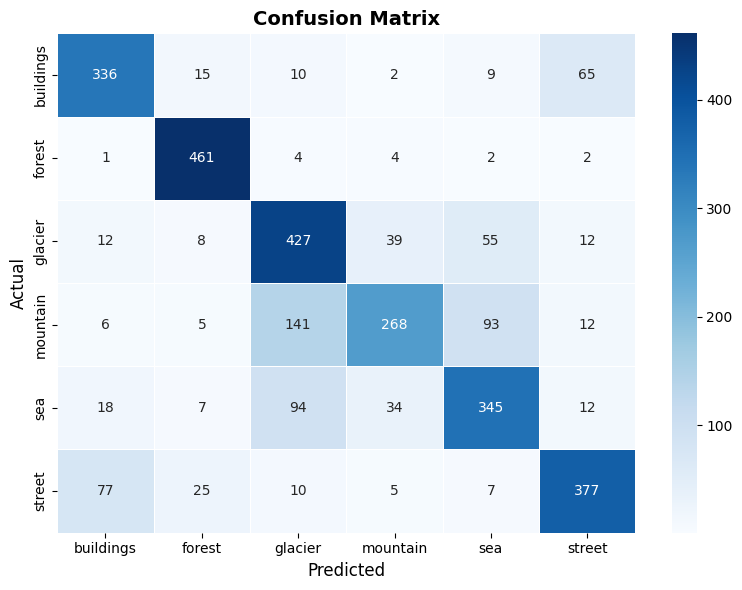

In [ ]:
cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names,
    cmap='Blues',
    linewidths=0.5
)
plt.xlabel("Predicted", fontsize=12)
plt.ylabel("Actual",    fontsize=12)
plt.title("Confusion Matrix", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

##  Step 13 — Sample Predictions (10 images)

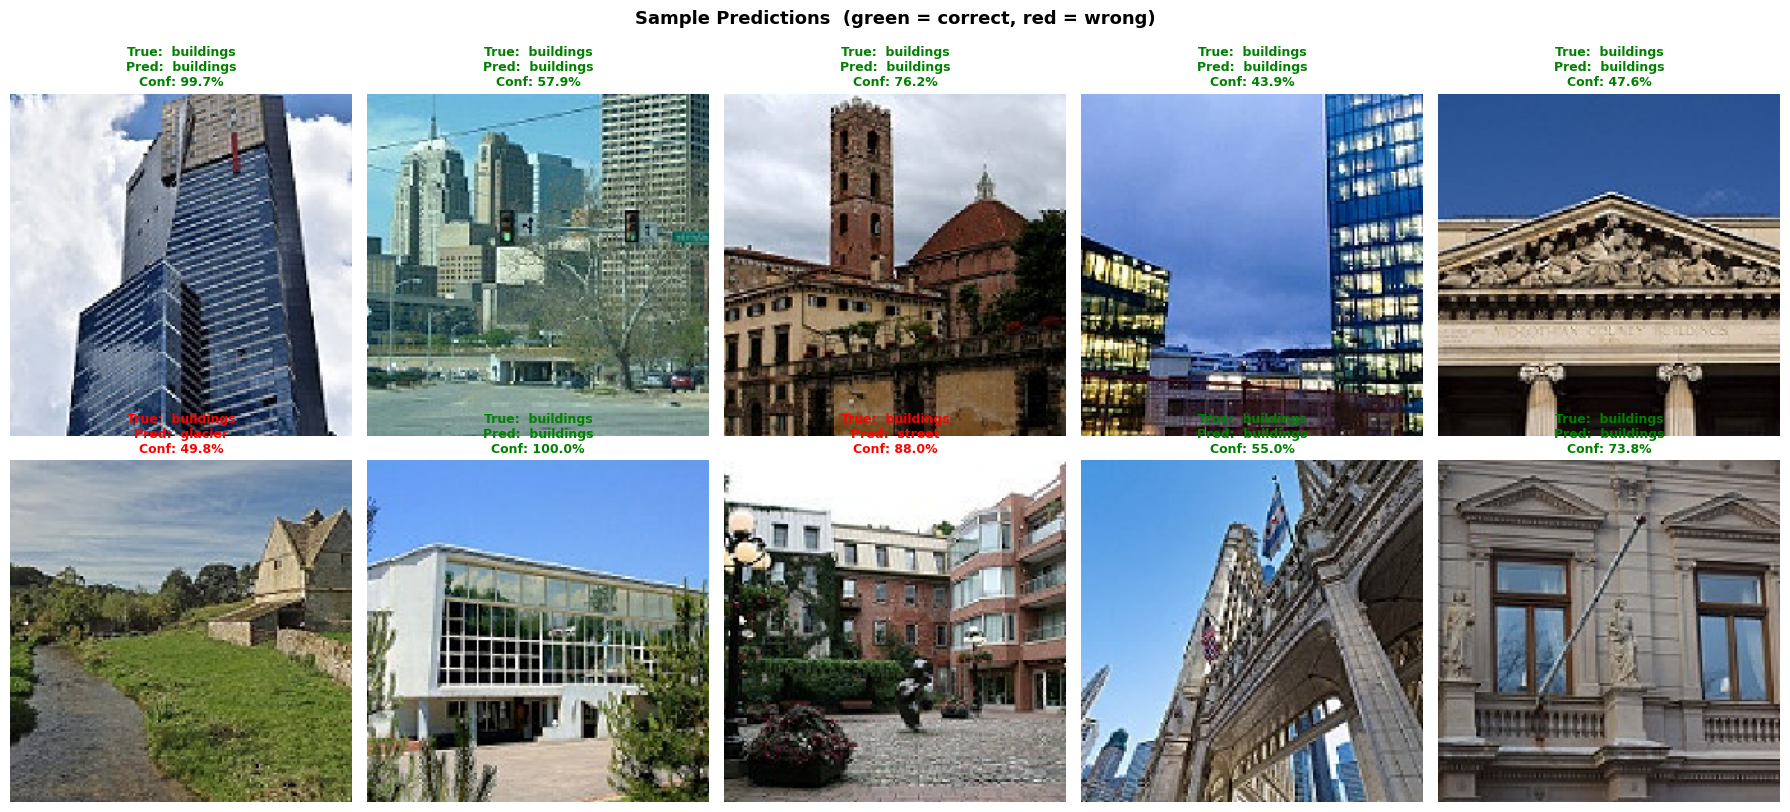

In [ ]:
test_generator.reset()
images, labels  = next(test_generator)
sample_preds    = model.predict(images, verbose=0)

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for i in range(10):
    actual     = class_names[np.argmax(labels[i])]
    predicted  = class_names[np.argmax(sample_preds[i])]
    confidence = np.max(sample_preds[i]) * 100

    axes[i].imshow(images[i])
    color = 'green' if actual == predicted else 'red'
    axes[i].set_title(
        f"True:  {actual}\nPred:  {predicted}\nConf: {confidence:.1f}%",
        fontsize=9, color=color, fontweight='bold'
    )
    axes[i].axis("off")

plt.suptitle("Sample Predictions  (green = correct, red = wrong)", fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

##  Step 14 — Reload Best Model for Grad-CAM
Reloading the best checkpoint (`best_phase2.keras`) instead of the last-epoch weights,
ensuring Grad-CAM uses the highest-accuracy model.

In [ ]:
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1. Load your saved model checkpoint
# Ensure the filename matches what you passed to ModelCheckpoint in Phase 2
model_path = "best_phase2.keras"  # or "resnet50_gradcam_improved.keras"

if os.path.exists(model_path):
    model = tf.keras.models.load_model(model_path)
    print("Model reloaded successfully!")
else:
    print(f"Error: '{model_path}' not found. Did the Colab runtime restart?")

# 2. Restore class_names using dataset_path from kagglehub
test_dir = os.path.join(dataset_path, "seg_test/seg_test")

_tmp = ImageDataGenerator(rescale=1./255).flow_from_directory(
    test_dir, target_size=(224, 224), batch_size=1, shuffle=False
)
class_names = list(_tmp.class_indices.keys())
print("class_names:", class_names)

Model reloaded successfully!
Found 3000 images belonging to 6 classes.
class_names: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


##  Step 15 — Grad-CAM Function


In [ ]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    """
    Generate a Grad-CAM heatmap.

    Parameters
    ----------
    img_array            : np.ndarray, shape (1, H, W, 3), float32 in [0, 1]
    model                : trained Keras model
    last_conv_layer_name : str  — name of the last convolutional layer
    pred_index           : int or None — class to explain (None = top prediction)

    Returns
    -------
    heatmap : np.ndarray, shape (H', W'), values in [0, 1]
    """
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, preds = grad_model(img_array)

        tape.watch(conv_outputs)

        if pred_index is None:
            pred_index = int(tf.argmax(preds[0]))

        class_channel = preds[:, pred_index]

    grads        = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # ReLU — keep only positive activations
    heatmap = tf.maximum(heatmap, 0)

    # Normalise to [0, 1] — epsilon prevents division-by-zero
    max_val = tf.math.reduce_max(heatmap)
    heatmap = heatmap / (max_val + 1e-8)

    return heatmap.numpy()

print("Grad-CAM function defined ")

Grad-CAM function defined 


##  Step 16 — Load Test Image
Update `img_path` to point to any image from your test set.

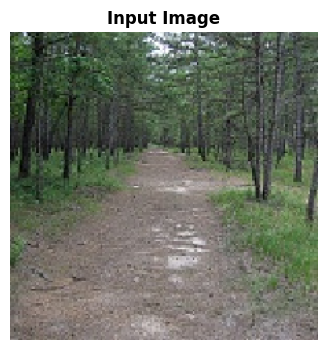

Image loaded   array shape: (1, 224, 224, 3)


In [ ]:
import os

# ── Change this path to any image in the test directory ──────────────
# img_path = "/content/seg_test/seg_test/forest/20056.jpg"
img_path = os.path.join(test_dir, "forest/20056.jpg")
# ─────────────────────────────────────────────────────────────────────

assert os.path.exists(img_path), (
    f"Image not found: {img_path}\n"
    "Update img_path to a valid image in your test directory."
)

# Load with Keras → RGB (matches model training colour space)
img_keras = tf.keras.utils.load_img(img_path, target_size=(224, 224))
img_array = tf.keras.utils.img_to_array(img_keras)
img_array = np.expand_dims(img_array, axis=0) / 255.0  # shape: (1, 224, 224, 3)

plt.figure(figsize=(4, 4))
plt.imshow(img_keras)
plt.title("Input Image", fontweight='bold')
plt.axis("off")
plt.show()

print(f"Image loaded   array shape: {img_array.shape}")

##  Step 17 — Generate Grad-CAM Heatmap

In [ ]:
last_conv_layer_name = "conv5_block3_out"  # Last conv layer of ResNet50

heatmap = make_gradcam_heatmap(img_array, model, last_conv_layer_name)

pred_probs_single = model.predict(img_array, verbose=0)[0]
pred_class_idx    = int(np.argmax(pred_probs_single))
pred_class_name   = class_names[pred_class_idx]
confidence        = float(np.max(pred_probs_single)) * 100

print(f"Predicted class : {pred_class_name}  ({confidence:.1f}% confidence)")
print(f"Heatmap shape   : {heatmap.shape}")
print(f"Heatmap range   : [{heatmap.min():.4f}, {heatmap.max():.4f}]")

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


Predicted class : forest  (98.7% confidence)
Heatmap shape   : (7, 7)
Heatmap range   : [0.0000, 1.0000]


##  Step 18 — Overlay Heatmap on Image
OpenCV is used **only** for the colour overlay (BGR blending).  
Model inference always uses the Keras RGB loader for colour-space consistency.

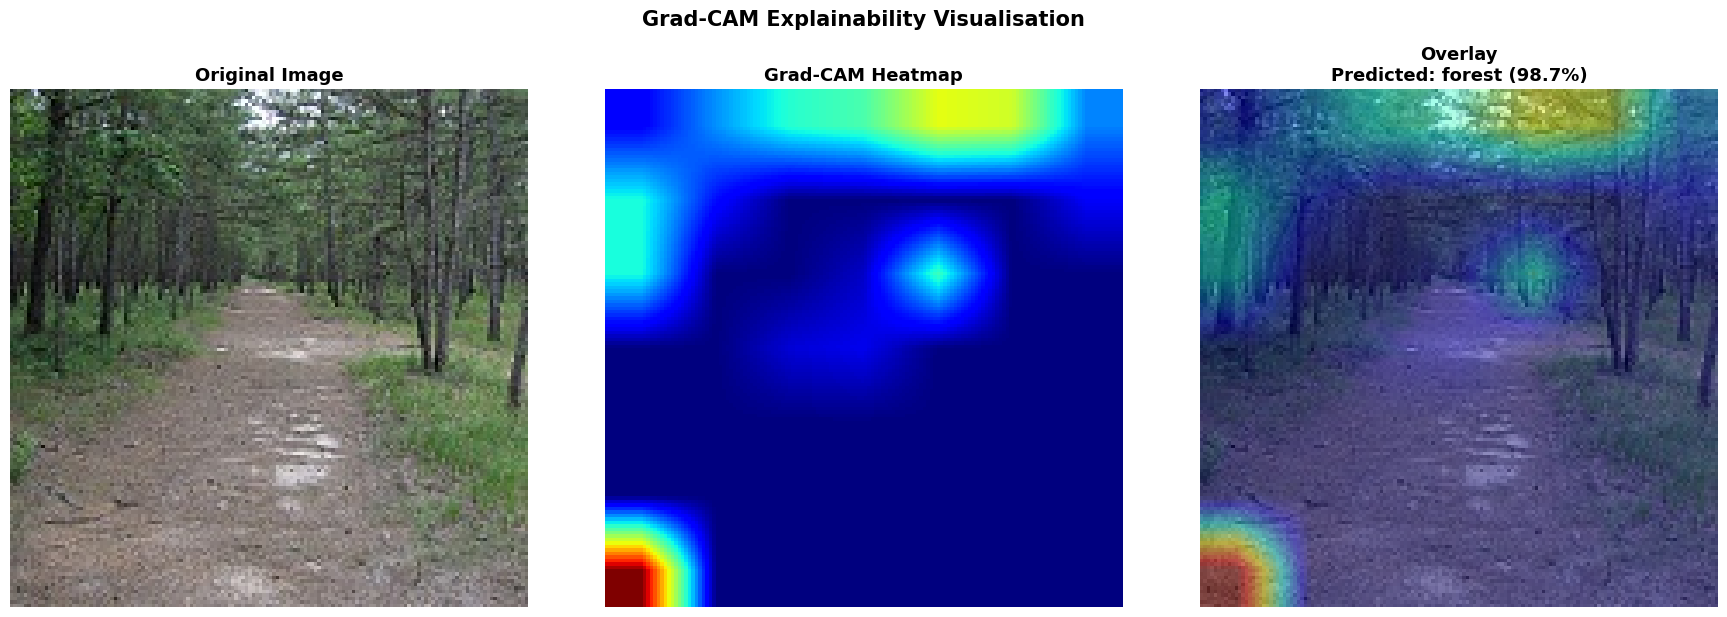

In [ ]:

img_bgr = cv2.imread(img_path)
if img_bgr is None:
    raise FileNotFoundError(
        f"OpenCV could not read: {img_path}\n"
        "Check the path and ensure the file is a supported image format (JPG/PNG)."
    )

heatmap_resized = cv2.resize(heatmap, (img_bgr.shape[1], img_bgr.shape[0]))
heatmap_uint8   = np.uint8(255 * heatmap_resized)

heatmap_colored = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
superimposed    = cv2.addWeighted(img_bgr, 0.6, heatmap_colored, 0.4, 0)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Image", fontsize=13, fontweight='bold')
axes[0].axis("off")

axes[1].imshow(heatmap_resized, cmap='jet')
axes[1].set_title("Grad-CAM Heatmap", fontsize=13, fontweight='bold')
axes[1].axis("off")

axes[2].imshow(cv2.cvtColor(superimposed, cv2.COLOR_BGR2RGB))
axes[2].set_title(
    f"Overlay\nPredicted: {pred_class_name} ({confidence:.1f}%)",
    fontsize=13, fontweight='bold'
)
axes[2].axis("off")

plt.suptitle("Grad-CAM Explainability Visualisation", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

##  Step 19 — Grad-CAM on Multiple Test Images
Runs Grad-CAM on the first 6 images from the test generator.  


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


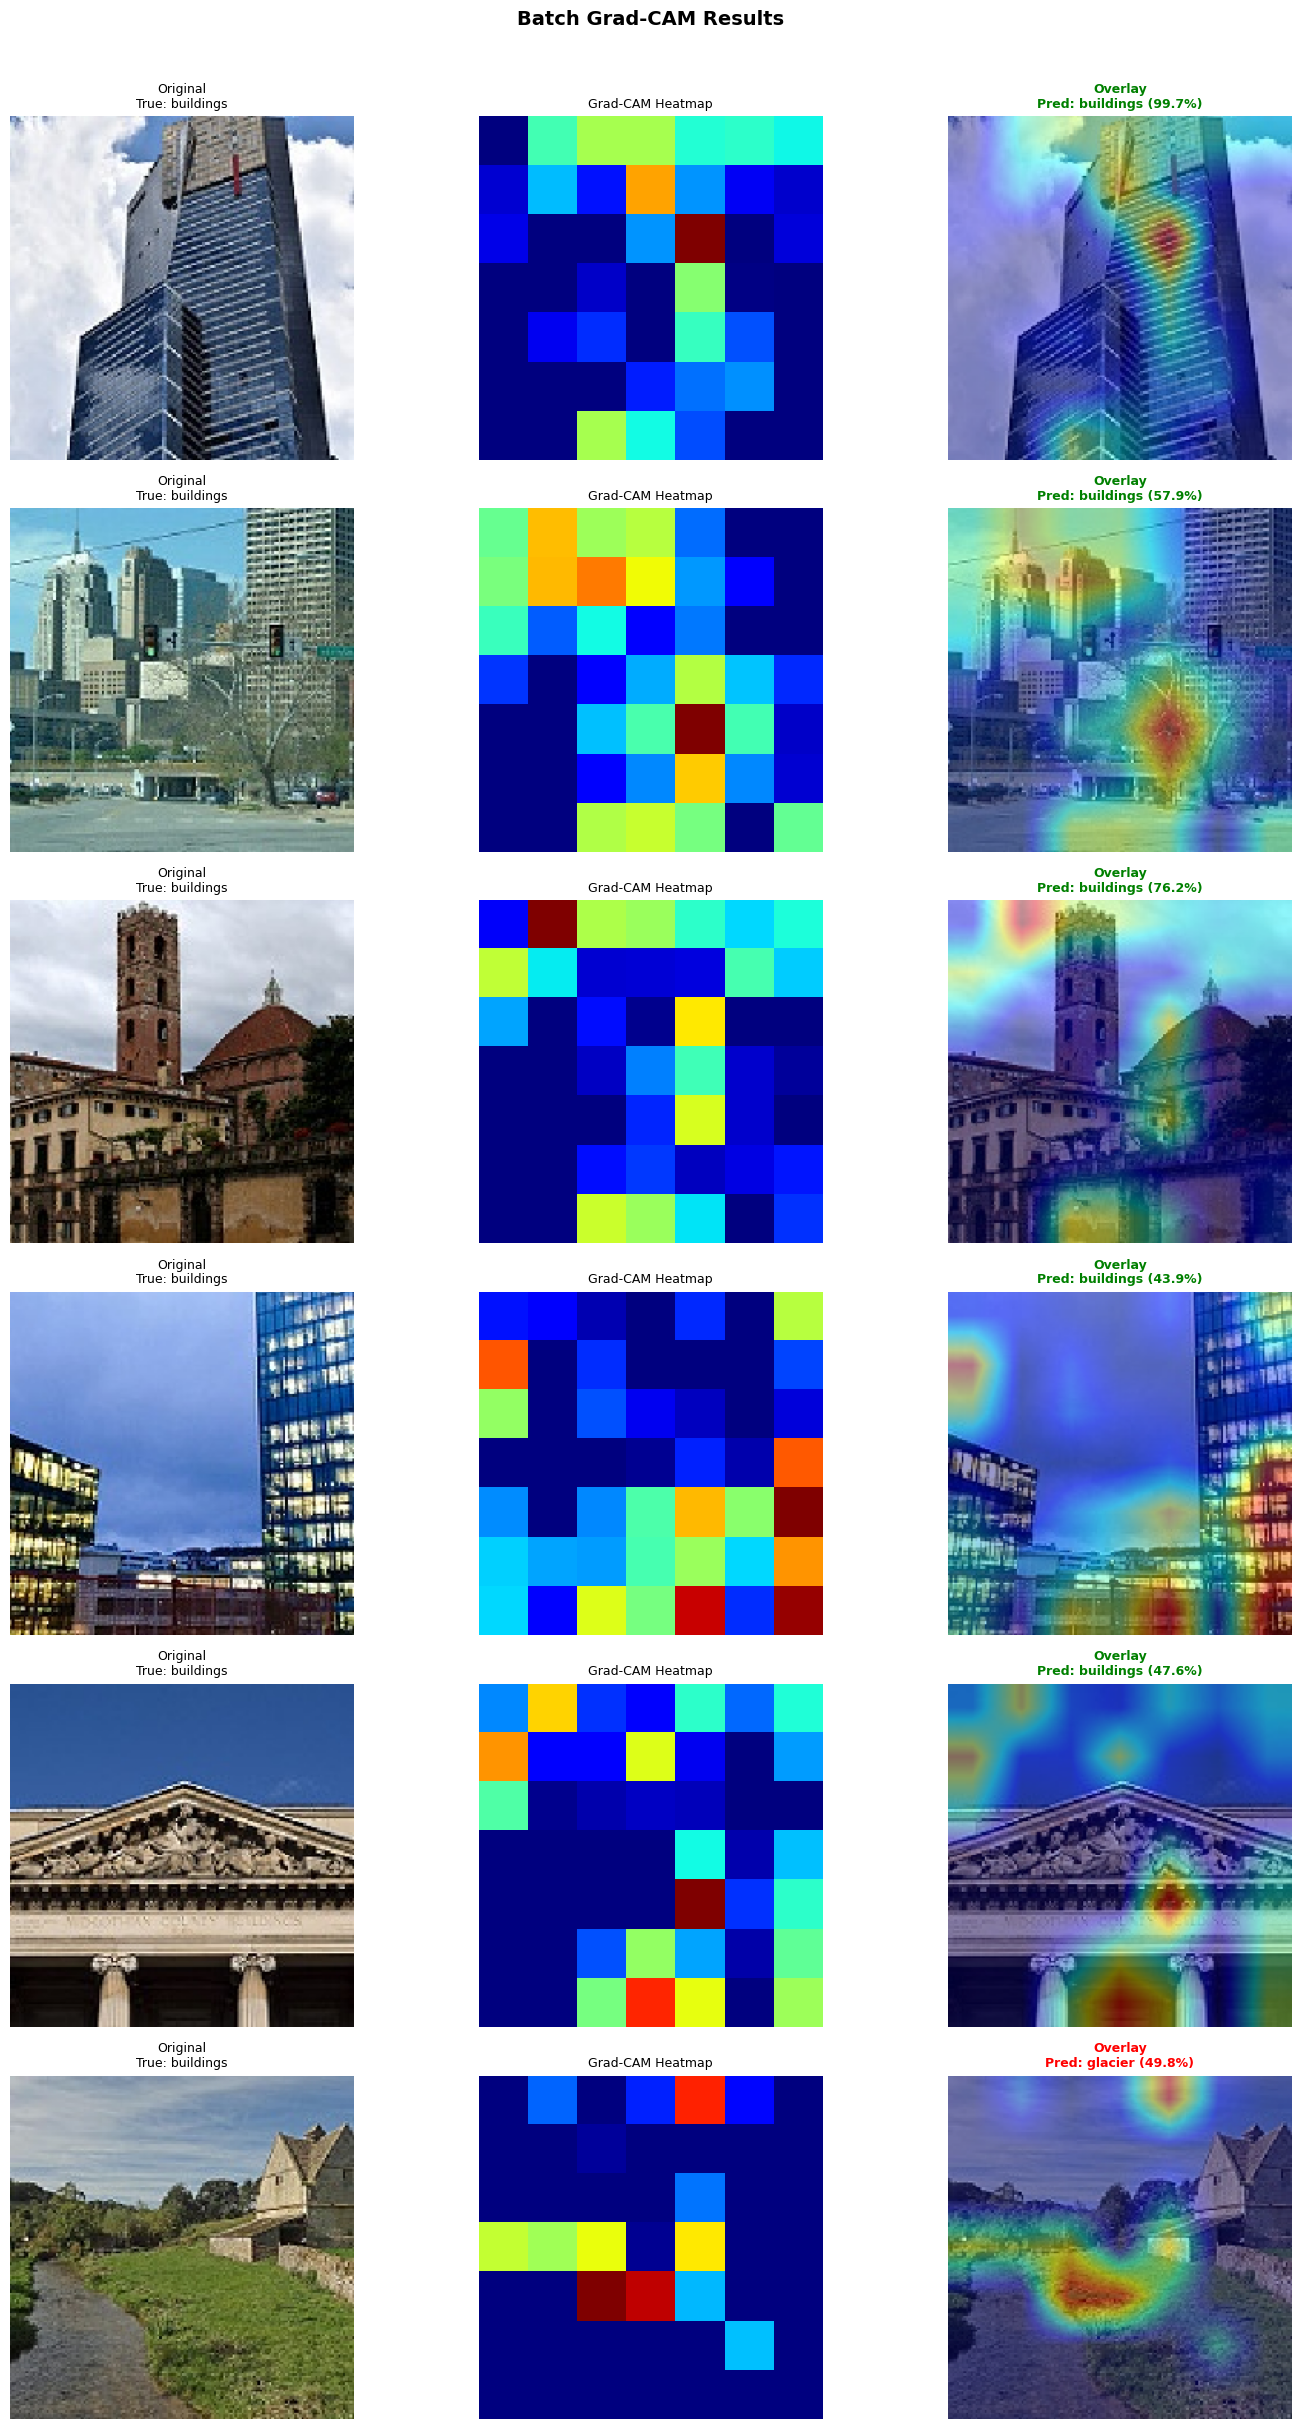

In [ ]:
test_generator.reset()
images_batch, labels_batch = next(test_generator)

n_show = 6
fig, axes = plt.subplots(n_show, 3, figsize=(15, n_show * 4))

for i in range(n_show):
    single_img = np.expand_dims(images_batch[i], axis=0)  # (1, 224, 224, 3)
    hm         = make_gradcam_heatmap(single_img, model, last_conv_layer_name)

    actual = class_names[np.argmax(labels_batch[i])]

    # Single predict call — reuse for both class name and confidence
    probs_i    = model.predict(single_img, verbose=0)[0]
    pred_idx   = int(np.argmax(probs_i))
    pred_name  = class_names[pred_idx]
    conf       = float(np.max(probs_i)) * 100

    # Original
    axes[i, 0].imshow(images_batch[i])
    axes[i, 0].set_title(f"Original\nTrue: {actual}", fontsize=9)
    axes[i, 0].axis("off")

    # Heatmap
    axes[i, 1].imshow(hm, cmap='jet')
    axes[i, 1].set_title("Grad-CAM Heatmap", fontsize=9)
    axes[i, 1].axis("off")

    # Overlay
    img_uint8   = np.uint8(images_batch[i] * 255)
    img_bgr_i   = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2BGR)
    hm_resized  = cv2.resize(hm, (img_bgr_i.shape[1], img_bgr_i.shape[0]))
    hm_uint8    = np.uint8(255 * hm_resized)
    hm_colored  = cv2.applyColorMap(hm_uint8, cv2.COLORMAP_JET)
    overlay     = cv2.addWeighted(img_bgr_i, 0.6, hm_colored, 0.4, 0)
    overlay_rgb = cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)

    color = 'green' if actual == pred_name else 'red'
    axes[i, 2].imshow(overlay_rgb)
    axes[i, 2].set_title(
        f"Overlay\nPred: {pred_name} ({conf:.1f}%)",
        fontsize=9, color=color, fontweight='bold'
    )
    axes[i, 2].axis("off")

plt.suptitle("Batch Grad-CAM Results", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()